In [1]:
"""
-- posibles librerias a instalar 
!pip install duckdb
!pip install google-api-python-client python-dotenv
!pip install "nbformat>=4.2.0"
""" 

'\n-- posibles librerias a instalar \n!pip install duckdb\n!pip install google-api-python-client python-dotenv\n!pip install "nbformat>=4.2.0"\n'

In [2]:
# imports 
import socket
from sklearn.decomposition import PCA
import umap
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb 
import pandas as pd
import numpy as np
import plotly.io as pio
pio.renderers.default = "vscode"


In [3]:
# esto era pa mi compu y las solicitudes a la api  probablemente se puede ignorar, pero lo dejo por si acaso.
_orig_getaddrinfo = socket.getaddrinfo
def _ipv4_only(host, port, family=0, *args, **kwargs):
    return _orig_getaddrinfo(host, port, socket.AF_INET, *args, **kwargs)
socket.getaddrinfo = _ipv4_only

In [4]:
# duckdb sirve para leer parquet mejor q pandas. 

cnx = duckdb.connect()
p = "'data/yt8m_sample.parquet'"

a = cnx.sql(f"DESCRIBE SELECT * FROM {p}")

b= cnx.sql(f"SELECT count(*) videos, avg(len(labels)) labels_x_video FROM {p}")
cnx.sql("""CREATE TABLE vocab AS
           SELECT * FROM read_csv('https://research.google.com/youtube8m/csv/2/vocabulary.csv')""")


In [5]:
a

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ pid         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ labels      │ BIGINT[]    │ YES     │ NULL    │ NULL    │ NULL    │
│ mean_rgb    │ FLOAT[]     │ YES     │ NULL    │ NULL    │ NULL    │
│ mean_audio  │ FLOAT[]     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [6]:
b

┌────────┬────────────────────┐
│ videos │   labels_x_video   │
│ int64  │       double       │
├────────┼────────────────────┤
│  41393 │ 3.0233372792501148 │
└────────┴────────────────────┘

In [7]:
c = cnx.sql(f"""
SELECT v.Vertical1, count(DISTINCT s.pid) AS videos
FROM (SELECT pid, unnest(labels) AS lbl FROM {p}) s
JOIN vocab v ON v.Index = s.lbl
GROUP BY 1 ORDER BY 2 DESC
""")
c

┌─────────────────────────┬────────┐
│        Vertical1        │ videos │
│         varchar         │ int64  │
├─────────────────────────┼────────┤
│ Arts & Entertainment    │  16593 │
│ Games                   │  10436 │
│ Autos & Vehicles        │   5466 │
│ Sports                  │   5397 │
│ Computers & Electronics │   3265 │
│ Business & Industrial   │   3051 │
│ Hobbies & Leisure       │   2308 │
│ Food & Drink            │   1785 │
│ Pets & Animals          │   1620 │
│ Shopping                │   1443 │
│    ·                    │     ·  │
│    ·                    │     ·  │
│    ·                    │     ·  │
│ Law & Government        │    462 │
│ (Unknown)               │    415 │
│ Reference               │    329 │
│ News                    │    281 │
│ People & Society        │    276 │
│ Jobs & Education        │    260 │
│ Books & Literature      │    169 │
│ Real Estate             │    120 │
│ Health                  │    108 │
│ Finance                 │     49 │
└

In [8]:
z= cnx.sql(f"""
SELECT v.Name, count(*) AS n
FROM (SELECT unnest(labels) AS lbl FROM {p}) s
JOIN vocab v ON v.Index = s.lbl
GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""")
z


┌─────────────────┬───────┐
│      Name       │   n   │
│     varchar     │ int64 │
├─────────────────┼───────┤
│ Game            │  8453 │
│ Video game      │  5845 │
│ Vehicle         │  4426 │
│ Concert         │  3967 │
│ Musician        │  3073 │
│ Cartoon         │  2553 │
│ Performance art │  2109 │
│ Car             │  2040 │
│ Dance           │  1899 │
│ Guitar          │  1689 │
└─────────────────┴───────┘
  10 rows       2 columns

/var/folders/cw/q3kmrhcj05j6p8f0f9dpby7r0000gn/T/ipykernel_68178/2471694795.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


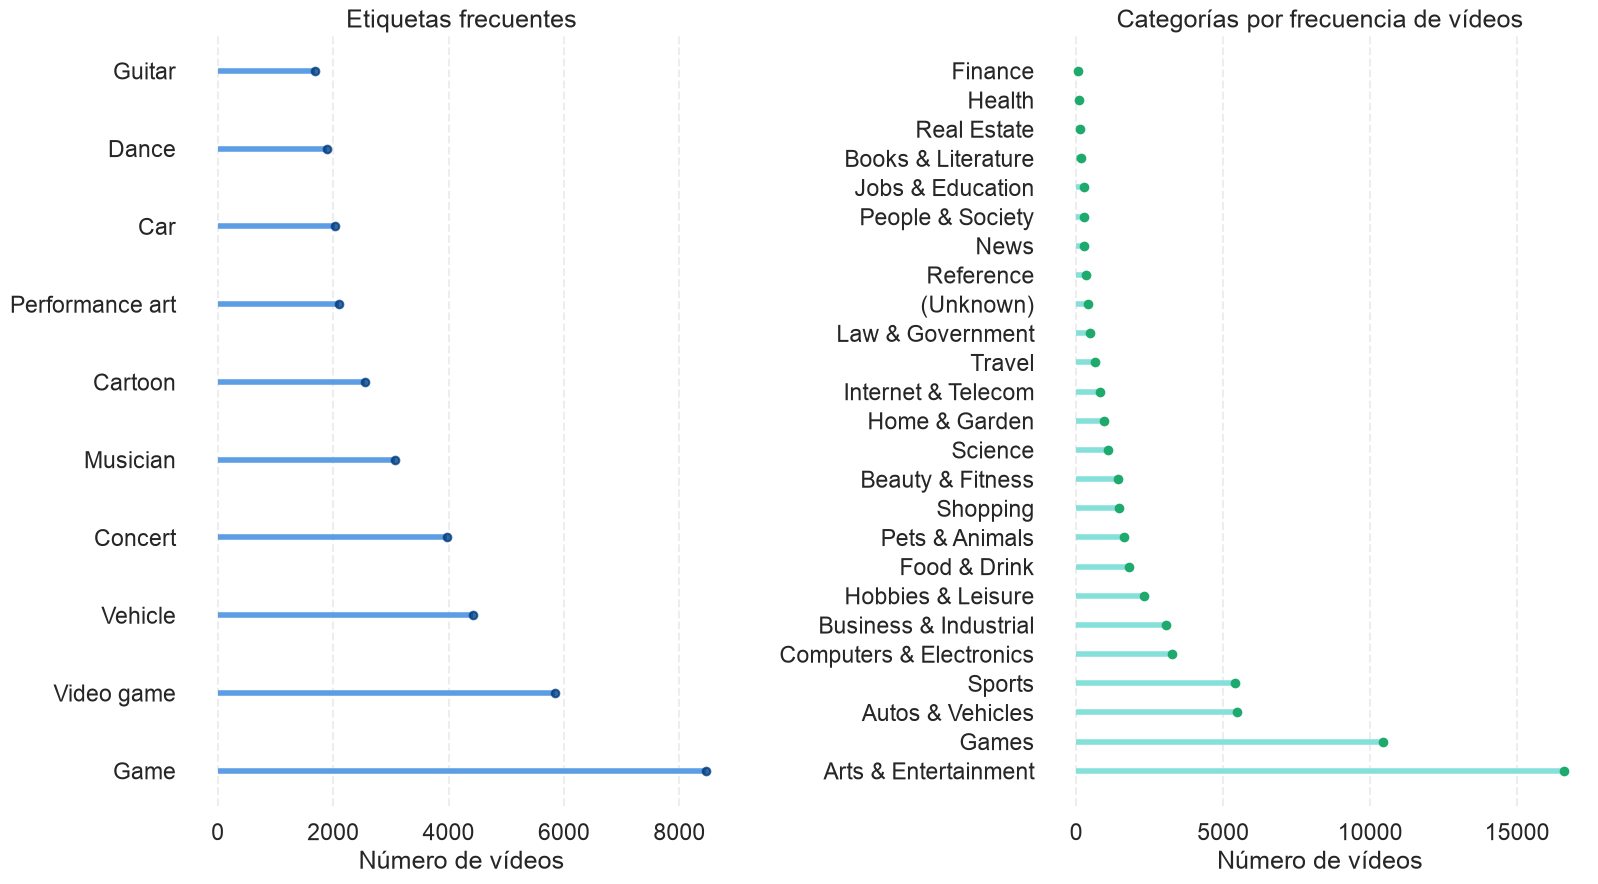

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

labels = z.df().sort_values("n")
categories = c.df().sort_values("videos")

fig, ax = plt.subplots(
    1,
    2,
    figsize=(18, 10),
    gridspec_kw={"wspace": 0.6},
)

# Frequent labels: lollipop chart
y = range(len(labels))
ax[0].hlines(y=y, xmin=0, xmax=labels["n"], color="#5C9DE3", linewidth=4)
ax[0].scatter(labels["n"], y, color="#033F83CB", s=30, zorder=3)
ax[0].set_yticks(y)
ax[0].set_yticklabels(labels["Name"])
ax[0].set_title("Etiquetas frecuentes")
ax[0].set_xlabel("Número de vídeos")
ax[0].set_ylabel("")
ax[0].invert_yaxis()

# Categories: lollipop chart
y = range(len(categories))
ax[1].hlines(y=y, xmin=0, xmax=categories["videos"], color="#86E0DA", linewidth=4)
ax[1].scatter(categories["videos"], y, color="#1EA96D", s=30, zorder=3)
ax[1].set_yticks(y)
ax[1].set_yticklabels(categories["Vertical1"])
ax[1].set_title("Categorías por frecuencia de vídeos")
ax[1].set_xlabel("Número de vídeos")
ax[1].set_ylabel("")
ax[1].invert_yaxis()

for axis in ax:
    axis.grid(axis="x", linestyle="--", alpha=0.35)
    axis.grid(axis="y", visible=False)
    sns.despine(ax=axis, left=True, bottom=True)

plt.tight_layout()


In [10]:

df = duckdb.sql("""
    SELECT h.*, s.mean_rgb, s.mean_audio
    FROM 'data/yt8m_hydrated.parquet' h
    JOIN 'data/yt8m_sample.parquet' s USING (pid)
    WHERE h.title IS NOT NULL
""").df()

df

,pid,labels,youtube_id,title,description,tags,category_id,channel_id,channel_title,published_at,...,view_count,like_count,comment_count,duration,definition,caption,topic_categories,fetched_at,mean_rgb,mean_audio
0,eACj,"[180, 304]",-04_3RVWD7o,SOG Cutlass Machete,,[],24,UCE4T89-csd3E3WGgDdbRyLg,karambit5,2014-05-04T17:54:50Z,...,3009.0,10.0,10.0,PT2M10S,sd,false,"[https://en.wikipedia.org/wiki/Hobby, https://...",2026-10-09T13:52:24.953058+00:00,"[0.34214902, 1.0072957, -0.28980112, -0.324092...","[-1.5312055, -1.0285152, 0.15257615, -1.395379..."
1,ftCj,"[1, 16, 189]",-0zrpo2QPPQ,star wars the clone wars episode 1 (on swedich...,star wars the clone wars episode 1,"[star, wars, the, clone]",24,UCMZoCU3WkIWT7bKV5SLAiYQ,beginnerimean,2009-03-09T15:39:39Z,...,1905.0,1.0,0.0,PT7M5S,sd,false,"[https://en.wikipedia.org/wiki/Entertainment, ...",2026-10-09T13:52:24.953058+00:00,"[0.3025053, -1.2443705, -0.23736396, 0.1390020...","[-0.2511156, -0.11014828, 1.0271589, -0.048605..."
2,VDCj,"[9, 10, 34]",-266lMiP8eI,혜민쌤의 스트럼스타일 전람회의 [기억의습작] 2,더많은 강좌영상과 악보를 보실려면\nhttp://cafe.naver.com/stru...,"[acoustic, guitar, 혜민쌤, 짜파게티, 어쉼, 어쿠스틱쉼터, 스트럼,...",10,UCWwM5caKb44ZWoUNV-wxaMg,스트럼스타일StrumStyle,2012-09-26T04:10:32Z,...,16625.0,26.0,1.0,PT2M7S,sd,false,"[https://en.wikipedia.org/wiki/Music, https://...",2026-10-09T13:52:24.541026+00:00,"[-1.7680979, 1.498631, 0.5506074, -0.19573559,...","[0.07566186, -0.67167705, 1.2172741, -0.376003..."
3,xNCj,[14],oxAsv4jkrNQ,D.I.S.C.O MV - YeomJungHwa ft. T.O.P,this is the mv of disco with chinese substitle...,"[pop, korean, bigbang, top, yeomjunghwa, 严正花]",10,UCa_kl3Jl9610-msXhgGHgWA,summer0berry,2008-07-06T07:03:43Z,...,3349.0,2.0,0.0,PT3M30S,sd,false,"[https://en.wikipedia.org/wiki/Music, https://...",2026-10-09T13:52:25.155348+00:00,"[0.30547825, -0.31106704, 0.5400254, -0.554503...","[1.3712485, -0.41870478, -0.80003065, 0.507905..."
4,FaCj,"[15, 18, 87, 545, 1751, 1779]",ESohw5NGtBw,Magnum Shahntae Arabian Mare For Sale,MAGNUM SHAHNTAE { Magnum Psyche X Eliticia Bey...,"[Magnum Shahntae, Premier Arabians]",15,UCtszPL2AXBiSwyOphq9vozw,ColoradoGoldAuto,2012-04-02T02:46:37Z,...,1386.0,5.0,0.0,PT3M3S,sd,false,[],2026-10-09T13:52:24.201171+00:00,"[-0.46667588, 0.47595778, -0.53944993, 0.30778...","[0.82242733, -0.7712296, 0.18220444, 0.0538855..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34783,4PI1,"[2, 44, 46, 64, 113, 119, 186, 425]",2XnicO002PU,Frederic Hanisch - First flight with Logo Xxtreme,,[00000],17,UCDWt6UZrwqjR_qEZD9FlCdA,Michael Wisbacher,2011-08-22T17:03:39Z,...,1784.0,1.0,0.0,PT4M13S,hd,false,[https://en.wikipedia.org/wiki/Hobby],2026-10-09T14:04:44.653228+00:00,"[-0.4823371, 1.0135632, -0.90189844, 1.3169345...","[-1.1823913, 1.3622572, -1.4978528, -1.2971554..."
34784,wHI1,"[709, 1265, 2160]",jj62fSuY4Vw,Mad Science- Gummy Bears,A Mad Science Episode,"[gummie, bears, gooey, water, microwave]",23,UCj6mxOEHEoplIzua40mWTGg,Prinstonx,2011-08-21T16:26:36Z,...,1873.0,10.0,NaN,PT3M55S,sd,false,[https://en.wikipedia.org/wiki/Lifestyle_(soci...,2026-10-09T14:08:01.601700+00:00,"[0.12847614, 0.6518212, -0.5436204, -0.7182475...","[-0.74331874, -0.8844952, 0.6554411, -1.124481..."
34785,1NI1,[8],ZtG19JeNpGM,2014 統一全日本ダンス選手権大会 織田慶治 渡辺理子 引退,2014年11月3日統一全日本プロフェッショナルダンス選手権大会で\n織田慶治・渡辺理子 組...,[],17,UC7NgdHUhRxi_ii9Ndd_KnXg,777jpan,2014-11-07T12:47:01Z,...,9380.0,25.0,0.0,PT4M48S,hd,false,"[https://en.wikipedia.org/wiki/Music, https://...",2026-10-09T14:04:32.302383+00:00,"[0.4772803, 0.5341225, 1.5690887, -0.6629534, ...","[-0.7775124, 1.4349083, 1.354236, 0.9293401, 0..."
34786,I5I1,"[9, 10, 34]",ZzRv1Iq2g7A,Bubbly - Colbie Caillat (and 6 other songs in A),these are a bunch of songs ive noticed can be ...,"[acoustic, bubbly, guthrie, hohlen, matter, ig...",10,UCwBTSSB4_djc9rgvANu4E9A,ghohlen01,2008-03-13T02:45:34Z,...,12499.0,20.0,2.0,PT3M52S,sd,false,[https://en.wikipedia.org/wiki/Independent_mus...,2026-10-09T14:05:33.345644+00:00,"[-1.7623701, 1.4740735, 0.549

In [11]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 34788 entries, 0 to 34787
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pid               34788 non-null  str    
 1   labels            34788 non-null  object 
 2   youtube_id        34788 non-null  str    
 3   title             34788 non-null  str    
 4   description       34788 non-null  str    
 5   tags              34788 non-null  object 
 6   category_id       34788 non-null  str    
 7   channel_id        34788 non-null  str    
 8   channel_title     34788 non-null  str    
 9   published_at      34788 non-null  str    
 10  default_language  34788 non-null  str    
 11  audio_language    1831 non-null   str    
 12  thumbnail_url     34788 non-null  str    
 13  view_count        34781 non-null  float64
 14  like_count        34113 non-null  float64
 15  comment_count     33195 non-null  float64
 16  duration          34788 non-null  str    
 17  defi

In [12]:

duckdb.sql("DESCRIBE SELECT * FROM 'data/emb_text.parquet'")
# pid VARCHAR | youtube_id VARCHAR | emb FLOAT[]

duckdb.sql("SELECT pid, youtube_id, len(emb) AS dim FROM 'data/emb_text.parquet' LIMIT 5")


┌─────────┬─────────────┬───────┐
│   pid   │ youtube_id  │  dim  │
│ varchar │   varchar   │ int64 │
├─────────┼─────────────┼───────┤
│ eACj    │ -04_3RVWD7o │   768 │
│ ftCj    │ -0zrpo2QPPQ │   768 │
│ VDCj    │ -266lMiP8eI │   768 │
│ xNCj    │ oxAsv4jkrNQ │   768 │
│ FaCj    │ ESohw5NGtBw │   768 │
└─────────┴─────────────┴───────┘

In [13]:
e = pd.read_parquet("data/emb_text.parquet")
h = pd.read_parquet("data/yt8m_hydrated.parquet", columns=["pid", "title"])
e = e.merge(h, on="pid")
X = np.stack(e["emb"])          # (n_videos, 768)
print(X.shape, np.linalg.norm(X, axis=1)[:3])   # normas ≈ 1.0 (normalizados)

# vecinos más cercanos de un video (similitud coseno = producto punto)
i = 0
sims = X @ X[i] # producto punto entre el embedding del video i y todos los demás
print(f"Video: {e.title[i]} (pid={e.pid[i]})")
for j in np.argsort(-sims)[1:6]:
    print(f"{sims[j]:.2f}  {e.title[j]}")


(34788, 768) [1. 1. 1.]
Video: SOG Cutlass Machete (pid=eACj)
0.88  Leatherman supertool 300
0.88  Benchmade BM 940 Osborne Folding Knife Review
0.87  Pinkerton Neck knife review
0.87  Panabas
0.87  Off-road in a Chevy Tahoe


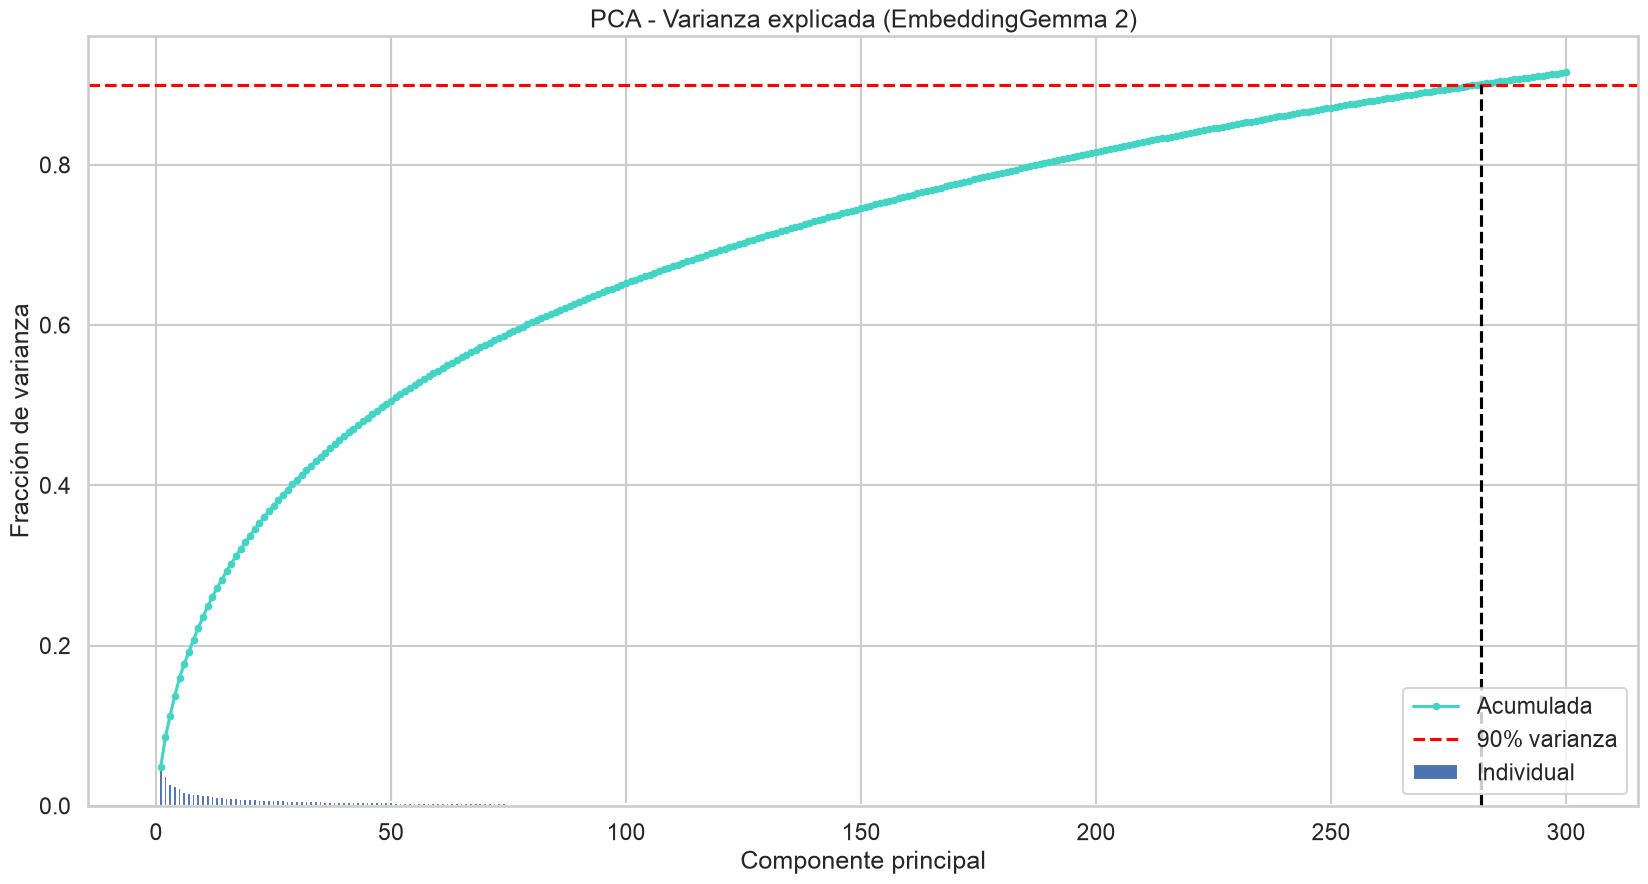

50% de varianza → 49 componentes
80% de varianza → 188 componentes
90% de varianza → 282 componentes
3 componentes explican 11.2%


In [14]:
pca = PCA().fit(X)
exp_var = pca.explained_variance_ratio_
cum_exp = np.cumsum(exp_var)

k_show = 300
fig, ax = plt.subplots(figsize=(20,10))
ax.bar(range(1, k_show+1), exp_var[:k_show], label="Individual")
ax.plot(range(1, k_show+1), cum_exp[:k_show], marker=".", label="Acumulada", color="#44D4C3")
ax.axhline(0.9, ls="--", c="red", label="90% varianza")
ax.vlines(x=np.argmax(cum_exp >= 0.9) + 1, ymin=0, ymax=0.9, ls="--", color="black")
ax.set_xlabel("Componente principal"); ax.set_ylabel("Fracción de varianza")
ax.set_title("PCA - Varianza explicada (EmbeddingGemma 2)"); ax.legend()
plt.show()

for t in (0.5, 0.8, 0.9):
    print(f"{t:.0%} de varianza → {np.argmax(cum_exp >= t) + 1} componentes")
print(f"3 componentes explican {cum_exp[2]:.1%}")



In [15]:
cat = duckdb.sql("""
    SELECT s.pid, mode(v.Vertical1) AS vertical
    FROM (SELECT pid, unnest(labels) AS lbl FROM 'data/yt8m_sample.parquet') s
    JOIN read_csv('https://research.google.com/youtube8m/csv/2/vocabulary.csv') v
      ON v.Index = s.lbl
    GROUP BY s.pid
""").df()

e = e.merge(cat, on="pid", how="left")
e["vertical"] = e["vertical"].fillna("(Unknown)")
assert len(e) == len(X)      # el merge no debe cambiar filas ni el orden
e["vertical"].value_counts().head(10)

vertical
Arts & Entertainment       12029
Games                       7243
Autos & Vehicles            3566
Sports                      2641
Food & Drink                1251
Business & Industrial       1142
Computers & Electronics     1076
Hobbies & Leisure           1053
Pets & Animals              1048
Beauty & Fitness             864
Name: count, dtype: int64

In [16]:
k90 = np.argmax(cum_exp >= 0.9) + 1          # 282
X_pca282 = PCA(n_components=k90, random_state=42).fit_transform(X)
P3 = PCA(n_components=3, random_state=42).fit_transform(X)
print(X_pca282.shape, P3.shape)  

(34788, 282) (34788, 3)


In [17]:
%%time
params = dict(n_components=3, metric="cosine", n_neighbors=15, min_dist=0.1, random_state=42)

U3      = umap.UMAP(**params).fit_transform(X)          # 768 → 3
U3_pca  = umap.UMAP(**params).fit_transform(X_pca282)   # 282 → 3


/opt/homebrew/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/opt/homebrew/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


CPU times: user 44.5 s, sys: 966 ms, total: 45.5 s
Wall time: 41.1 s


In [18]:
proj = e[["pid", "youtube_id", "title", "vertical"]].copy()
for name, Z in {"pca3": P3, "umap": U3, "pca282_umap": U3_pca}.items():
    proj[[f"{name}_x", f"{name}_y", f"{name}_z"]] = Z

proj.to_parquet("data/projections.parquet")
proj.head()

,pid,youtube_id,title,vertical,pca3_x,pca3_y,pca3_z,umap_x,umap_y,umap_z,pca282_umap_x,pca282_umap_y,pca282_umap_z
0,eACj,-04_3RVWD7o,SOG Cutlass Machete,Hobbies & Leisure,0.084029,0.083468,-0.098645,2.628729,7.649654,8.933794,3.184703,2.491624,8.095982
1,ftCj,-0zrpo2QPPQ,star wars the clone wars episode 1 (on swedich...,Arts & Entertainment,0.058628,-0.071004,0.044223,4.768191,4.595020,10.474703,5.609771,5.537461,7.398306
2,VDCj,-266lMiP8eI,혜민쌤의 스트럼스타일 전람회의 [기억의습작] 2,Arts & Entertainment,-0.096521,-0.051716,-0.150312,2.062567,0.483460,8.550847,0.736587,9.067015,9.215668
3,xNCj,oxAsv4jkrNQ,D.I.S.C.O MV - YeomJungHwa ft. T.O.P,Arts & Entertainment,-0.131939,-0.106059,0.011373,2.309696,-0.016760,7.857056,2.901830,9.862104,9.071431
4,FaCj,ESohw5NGtBw,Magnum Shahntae Arabian Mare For Sale,Pets & Animals,0.012328,0.084364,-0.017940,-0.377057,4.960883,10.295608,-1.338392,4.017670,7.262931


In [19]:
def plot3d(name):
    fig = px.scatter_3d(proj, x=f"{name}_x", y=f"{name}_y", z=f"{name}_z",
                        color="vertical", hover_name="title", opacity=0.6,
                        title=name, height=750)
    fig.update_traces(marker_size=2)
    return fig

plot3d("umap")          # cambia a "pca3" o "pca282_umap"


In [20]:
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier

y = proj["vertical"].to_numpy(dtype=str)
k = len(np.unique(y))                                   # n° de categorías → n° de clusters
rng = np.random.default_rng(42)
idx = rng.choice(len(X), 5000, replace=False)           # muestra para métricas O(n²)

reps = {"pca3": P3, "umap": U3, "pca282_umap": U3_pca, "original_768": X}

rows = []
for name, Z in reps.items():
    is_orig = name == "original_768"
    clusters = KMeans(n_clusters=k, n_init=5, random_state=42).fit_predict(Z)
    rows.append({
        "proyeccion": name,
        "trustworthiness": np.nan if is_orig else trustworthiness(X[idx], Z[idx], n_neighbors=15, metric="cosine"),
        "silhouette_vertical": silhouette_score(Z[idx], y[idx], metric="cosine" if is_orig else "euclidean"),
        "knn_acc_vertical": cross_val_score(
            KNeighborsClassifier(15, metric="cosine" if is_orig else "minkowski"), Z, y, cv=5).mean(),
        "ARI_kmeans": adjusted_rand_score(y, clusters),
        "NMI_kmeans": normalized_mutual_info_score(y, clusters),
    })

# baseline trivial: siempre predecir la categoría más común
rows.append({"proyeccion": "baseline_mayoria",
             "knn_acc_vertical": cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=5).mean()})

metricas = pd.DataFrame(rows).set_index("proyeccion").round(3)
metricas.to_csv("data/metricas_text.csv")
metricas



,trustworthiness,silhouette_vertical,knn_acc_vertical,ARI_kmeans,NMI_kmeans
proyeccion,,,,,
pca3,0.830,-0.160,0.638,0.121,0.323
umap,0.957,-0.163,0.764,0.143,0.360
pca282_umap,0.959,-0.171,0.769,0.155,0.377
original_768,NaN,0.008,0.793,0.137,0.346
baseline_mayoria,NaN,NaN,0.346,NaN,NaN


In [21]:
from sklearn.manifold import trustworthiness
from sklearn.metrics import normalized_mutual_info_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.cluster import KMeans
import umap

modelos = {
    "TF-IDF":            "data/emb_tfidf.parquet",
    "MiniLM":            "data/emb_minilm.parquet",
    "EmbeddingGemma 2":  "data/emb_text.parquet",
}

y = proj["vertical"].to_numpy(dtype=str)
k = len(np.unique(y))
idx = np.random.default_rng(42).choice(len(proj), 5000, replace=False)
umap_params = dict(n_components=3, metric="cosine", n_neighbors=15, min_dist=0.1, random_state=42)

rows, umaps = [], {}
for nombre, path in modelos.items():
    # 1. cargar y alinear por pid con proj (mismo orden de filas para todos los modelos)
    emb = pd.read_parquet(path, columns=["pid", "emb"])
    Xm = np.stack(proj[["pid"]].merge(emb, on="pid", how="left")["emb"])
    assert len(Xm) == len(proj)

    # 2. misma proyección para todos
    U = umap.UMAP(**umap_params).fit_transform(Xm)
    umaps[nombre] = U

    # 3. mismas métricas para todos
    clusters = KMeans(n_clusters=k, n_init=5, random_state=42).fit_predict(U)
    rows.append({
        "modelo": nombre,
        "dims": Xm.shape[1],
        "knn_acc_original": cross_val_score(KNeighborsClassifier(15, metric="cosine"), Xm, y, cv=5).mean(),
        "knn_acc_umap":     cross_val_score(KNeighborsClassifier(15), U, y, cv=5).mean(),
        "NMI_kmeans_umap":  normalized_mutual_info_score(y, clusters),
        "trustworthiness":  trustworthiness(Xm[idx], U[idx], n_neighbors=15, metric="cosine"),
    })
    print(f"✓ {nombre}")

metricas_modelos = pd.DataFrame(rows).set_index("modelo").round(3)
metricas_modelos.to_csv("data/metricas_modelos.csv")
metricas_modelos

/opt/homebrew/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✓ TF-IDF


/opt/homebrew/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✓ MiniLM


/opt/homebrew/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✓ EmbeddingGemma 2


,dims,knn_acc_original,knn_acc_umap,NMI_kmeans_umap,trustworthiness
modelo,,,,,
TF-IDF,768,0.605,0.558,0.132,0.870
MiniLM,384,0.693,0.669,0.294,0.887
EmbeddingGemma 2,768,0.793,0.764,0.360,0.957


In [27]:
CORTO = {"TF-IDF": "tfidf", "MiniLM": "minilm", "EmbeddingGemma 2": "gemma2"}

for nombre, U in umaps.items():
    c = CORTO[nombre]
    proj[[f"{c}_x", f"{c}_y", f"{c}_z"]] = U

proj.to_parquet("data/projections.parquet")
[c for c in proj.columns if c.endswith("_x")]

['pca3_x', 'umap_x', 'pca282_umap_x', 'tfidf_x', 'minilm_x', 'gemma2_x']

In [28]:
def plot3d_2(name, data=None, point_size=2, title=None):
    data = proj if data is None else data
    fig = px.scatter_3d(data, x=f"{name}_x", y=f"{name}_y", z=f"{name}_z",
                        color="vertical", hover_name="title", opacity=0.6,
                        title=title or name, height=750,
                        color_discrete_sequence=px.colors.qualitative.Alphabet,
                        category_orders={"vertical": data["vertical"].value_counts().index.tolist()})
    fig.update_traces(marker_size=point_size)
    fig.update_layout(legend=dict(itemsizing="constant", font_size=14, title_text="Categoría"))
    return fig

In [29]:
plot3d_2("tfidf", title="UMAP 3D · TF-IDF")

In [30]:
plot3d_2("minilm", title="UMAP 3D · MiniLM")